# 🏦 Banking Transaction Pattern Analysis

**Data Analytics Training Project**

## Problem Statement
Banks process a huge number of card transactions every day. A small share of them are fraudulent.
The bank wants to understand **how customers spend money** and **whether fraud follows any pattern**
(by merchant category, time, or amount), so it can improve monitoring and decision-making.

## Objectives
1. Clean and prepare the transaction data.
2. Understand spending patterns by merchant category, month and day of week.
3. Understand customer behaviour (how often customers transact, who spends the most).
4. Analyse fraud: how common it is and whether it is higher in any category, time or amount range.
5. Share findings, recommendations and limitations, and build an interactive Streamlit dashboard.

## Dataset
File: `transactions.csv` – **1,000,000 transactions** from the year 2023.

| Column | Meaning |
|---|---|
| transaction_id | Unique ID of the transaction |
| customer_id | ID of the customer who made it |
| transaction_timestamp | Date of the transaction |
| amount | Transaction amount ($) |
| merchant_category | Type of shop: electronics, fashion, gaming, groceries, travel |
| is_fraud | 1 = fraud, 0 = legitimate |
| year, month | Year and month of the transaction |

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# show all columns when printing a table
pd.set_option("display.max_columns", None)

# one colour theme for every chart (orange / red, same as the dashboard)
plt.style.use("ggplot")
ORANGE = "#FF8C00"
RED = "#E63946"
COLORS = ["#FF4B1F", "#FF8C00", "#FFB347", "#E63946", "#B71C1C"]

## 2. Load the Data and Take a Random Sample

The full file has 1,000,000 rows. To keep the analysis and dashboard fast, we work with a
**random sample of 100,000 rows**.

> **Why random?** An earlier version used `nrows=100000` (the *first* 100,000 rows).
> The file is not in date order, so those rows only covered **May, October and December**.
> A random sample covers the whole year and represents the full data fairly.
> `random_state=42` makes the sample the same every time we run the notebook.

In [2]:
# read the full dataset
full_df = pd.read_csv("transactions.csv")
print("Full dataset shape:", full_df.shape)

# take a random sample of 100,000 rows
df = full_df.sample(n=100000, random_state=42)

# reset the row numbers to 0, 1, 2, ...
df = df.reset_index(drop=True)

print("Sample shape:", df.shape)

Full dataset shape: (1000000, 8)
Sample shape: (100000, 8)


In [3]:
# check that the sample covers all 12 months
print("Months in full data:", sorted(full_df["month"].unique().tolist()))
print("Months in sample   :", sorted(df["month"].unique().tolist()))

# save the sample so it can be reused
df.to_csv("transactions_sample.csv", index=False)

Months in full data: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Months in sample   : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]


## 3. Data Overview

In [4]:
df.head()

,transaction_id,customer_id,transaction_timestamp,amount,merchant_category,is_fraud,year,month
0,333265,23339,2023-02-09T00:00:00.000+02:00,595.917929,electronics,0,2023,2
1,935249,10331,2023-10-07T00:00:00.000+02:00,172.133058,fashion,0,2023,10
2,166153,33300,2023-03-21T00:00:00.000+02:00,395.787539,groceries,0,2023,3
3,886360,16862,2023-12-11T00:00:00.000+02:00,845.291981,travel,0,2023,12
4,647099,12373,2023-10-30T00:00:00.000+02:00,209.689703,electronics,0,2023,10


In [5]:
df.tail()

,transaction_id,customer_id,transaction_timestamp,amount,merchant_category,is_fraud,year,month
99995,146672,40921,2023-01-04T00:00:00.000+02:00,630.494914,travel,0,2023,1
99996,405963,5024,2023-01-31T00:00:00.000+02:00,733.556001,travel,0,2023,1
99997,679903,52910,2023-02-19T00:00:00.000+02:00,178.734241,fashion,0,2023,2
99998,414283,38319,2023-09-29T00:00:00.000+02:00,112.875866,groceries,0,2023,9
99999,236513,20469,2023-03-02T00:00:00.000+02:00,988.254642,fashion,0,2023,3


In [6]:
print("Rows and Columns:", df.shape)
df.columns

Rows and Columns: (100000, 8)


Index(['transaction_id', 'customer_id', 'transaction_timestamp', 'amount',
       'merchant_category', 'is_fraud', 'year', 'month'],
      dtype='str')

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 8 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   transaction_id         100000 non-null  int64  
 1   customer_id            100000 non-null  int64  
 2   transaction_timestamp  100000 non-null  str    
 3   amount                 100000 non-null  float64
 4   merchant_category      100000 non-null  str    
 5   is_fraud               100000 non-null  int64  
 6   year                   100000 non-null  int64  
 7   month                  100000 non-null  int64  
dtypes: float64(1), int64(5), str(2)
memory usage: 9.6 MB


In [8]:
df.describe()

,transaction_id,customer_id,amount,is_fraud,year,month
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.0,100000.000000
mean,500523.156670,30038.111090,500.433511,0.029940,2023.0,6.533920
std,289056.000717,17372.236967,288.360245,0.170423,0.0,3.446132
min,3.000000,2.000000,0.001943,0.000000,2023.0,1.000000
25%,250901.250000,14967.000000,251.664541,0.000000,2023.0,4.000000
50%,500935.500000,30095.500000,499.871964,0.000000,2023.0,7.000000
75%,750357.000000,45108.250000,748.835699,0.000000,2023.0,10.000000
max,999994.000000,59999.000000,999.993318,1.000000,2023.0,12.000000


In [9]:
# count missing values in each column
df.isnull().sum()

transaction_id           0
customer_id              0
transaction_timestamp    0
amount                   0
merchant_category        0
is_fraud                 0
year                     0
month                    0
dtype: int64

**Observation:** There are 100,000 rows and 8 columns with **no missing values**.
`amount` ranges from almost \$0 to about \$1,000, and the mean (\$500) is almost equal to the median (\$500).

## 4. Data Cleaning

We check the data for common problems one by one and fix what is needed.

### 4.1 Convert timestamp to a date type

In [10]:
df["transaction_timestamp"] = pd.to_datetime(df["transaction_timestamp"])

print(df["transaction_timestamp"].dtype)
print("First date:", df["transaction_timestamp"].min())
print("Last date :", df["transaction_timestamp"].max())

datetime64[us, UTC+02:00]
First date: 2023-01-01 00:00:00+02:00
Last date : 2023-12-31 00:00:00+02:00


In [11]:
# does the data have time of day? (check which hours appear)
hours = df["transaction_timestamp"].dt.hour.unique()
print("Hours found in the data:", hours)

Hours found in the data: [0]


### 4.2 Duplicates

In [12]:
# completely identical rows
duplicate_rows = df.duplicated().sum()

# the same transaction_id used more than once
duplicate_ids = df["transaction_id"].duplicated().sum()

print("Duplicate rows           :", duplicate_rows)
print("Duplicate transaction IDs:", duplicate_ids)

Duplicate rows           : 0
Duplicate transaction IDs: 0


### 4.3 Invalid amounts

In [13]:
# an amount of 0 or less is not a valid transaction
invalid_amounts = (df["amount"] <= 0).sum()

print("Amounts <= 0:", invalid_amounts)
print("Smallest amount:", round(df["amount"].min(), 4))
print("Largest amount :", round(df["amount"].max(), 2))

Amounts <= 0: 0
Smallest amount: 0.0019
Largest amount : 999.99


### 4.4 Category names and IDs

In [14]:
# check spelling of merchant categories (no typos / extra spaces)
print("Merchant categories:", df["merchant_category"].unique())

# check the fraud column only has 0 and 1
print("is_fraud values:", df["is_fraud"].unique())

# check customer ID range
print("Customer ID range:", df["customer_id"].min(), "to", df["customer_id"].max())

# year column
print("Years:", df["year"].unique())

Merchant categories: <ArrowStringArray>
['electronics', 'fashion', 'groceries', 'travel', 'gaming']
Length: 5, dtype: str
is_fraud values: [0 1]
Customer ID range: 2 to 59999
Years: [2023]


### 4.5 Create new columns for analysis

In [15]:
# day number, month name and weekday name from the date
df["day"] = df["transaction_timestamp"].dt.day
df["month_name"] = df["transaction_timestamp"].dt.month_name()
df["day_name"] = df["transaction_timestamp"].dt.day_name()

# readable fraud label
df["fraud_status"] = df["is_fraud"].map({0: "Legitimate", 1: "Fraud"})

# group amounts into ranges
bins = [0, 100, 250, 500, 750, 1000]
labels = ["$0-100", "$100-250", "$250-500", "$500-750", "$750-1000"]
df["amount_range"] = pd.cut(df["amount"], bins=bins, labels=labels)

df.head()

,transaction_id,customer_id,transaction_timestamp,amount,merchant_category,is_fraud,year,month,day,month_name,day_name,fraud_status,amount_range
0,333265,23339,2023-02-09 00:00:00+02:00,595.917929,electronics,0,2023,2,9,February,Thursday,Legitimate,$500-750
1,935249,10331,2023-10-07 00:00:00+02:00,172.133058,fashion,0,2023,10,7,October,Saturday,Legitimate,$100-250
2,166153,33300,2023-03-21 00:00:00+02:00,395.787539,groceries,0,2023,3,21,March,Tuesday,Legitimate,$250-500
3,886360,16862,2023-12-11 00:00:00+02:00,845.291981,travel,0,2023,12,11,December,Monday,Legitimate,$750-1000
4,647099,12373,2023-10-30 00:00:00+02:00,209.689703,electronics,0,2023,10,30,October,Monday,Legitimate,$100-250


In [16]:
# save the cleaned data (used by the Streamlit dashboard)
df.to_csv("cleaned_transactions.csv", index=False)
print("Cleaned data saved:", df.shape)

Cleaned data saved: (100000, 13)


### Cleaning Summary

| Check | Result | Action |
|---|---|---|
| Missing values | None | No action needed |
| Duplicate rows / transaction IDs | 0 / 0 | No action needed |
| Amounts ≤ 0 | 0 | No action needed |
| Category spelling | 5 clean categories | No action needed |
| `is_fraud` values | Only 0 and 1 | No action needed |
| Timestamp type | Text | Converted to datetime |
| Time of day | Every transaction is at 00:00 | Only the **date** is usable, not the hour |
| `year` | Always 2023 | Kept, but not useful for analysis |
| New columns | – | Added `day`, `month_name`, `day_name`, `fraud_status`, `amount_range` |

The data was already quite clean, so most work was **checking** and **adding helpful columns**.

## 5. Exploratory Data Analysis (EDA)

### 5.1 Key Numbers

In [17]:
total_transactions = len(df)
unique_customers = df["customer_id"].nunique()
total_amount = df["amount"].sum()
average_amount = df["amount"].mean()
fraud_count = df["is_fraud"].sum()
fraud_rate = df["is_fraud"].mean() * 100

print("Total Transactions        :", total_transactions)
print("Unique Customers          :", unique_customers)
print("Total Transaction Amount  : $", round(total_amount, 2))
print("Average Transaction Amount: $", round(average_amount, 2))
print("Fraud Transactions        :", fraud_count)
print("Fraud Rate                :", round(fraud_rate, 2), "%")

Total Transactions        : 100000
Unique Customers          : 48630
Total Transaction Amount  : $ 50043351.1
Average Transaction Amount: $ 500.43
Fraud Transactions        : 2994
Fraud Rate                : 2.99 %


### 5.2 Merchant Categories

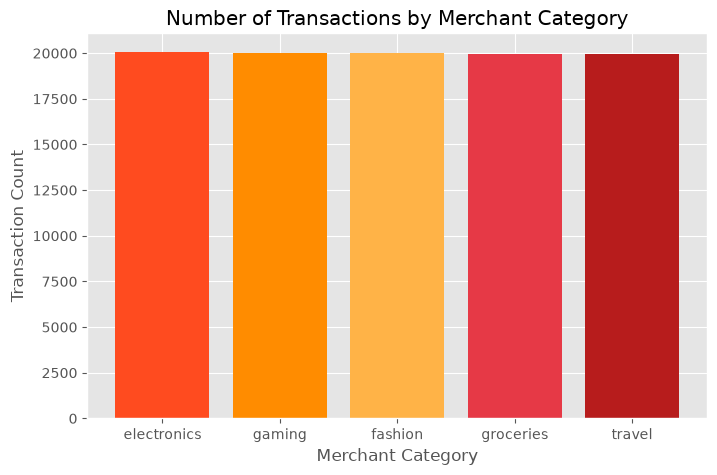

merchant_category
electronics    20079
gaming         19999
fashion        19995
groceries      19966
travel         19961
Name: count, dtype: int64

In [18]:
# number of transactions in each category
category_count = df["merchant_category"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(category_count.index, category_count.values, color=COLORS)
plt.title("Number of Transactions by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Transaction Count")
plt.show()

category_count

**Observation:** All 5 categories have almost the same number of transactions (about 20,000 each, ~20%).
No single category dominates customer activity.

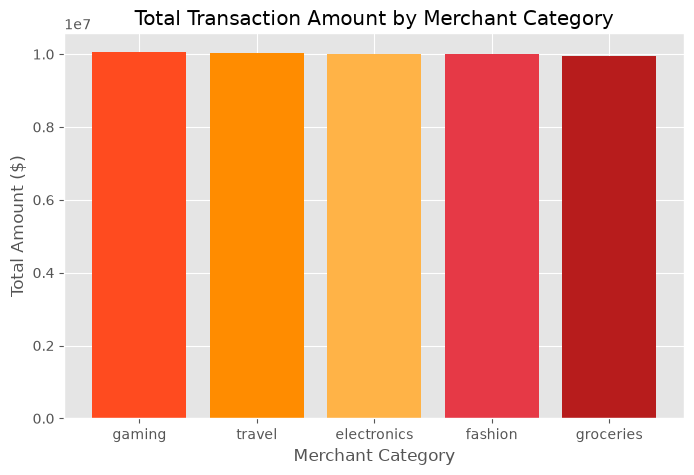

merchant_category
gaming         10066654.56
travel         10034587.00
electronics    10004587.57
fashion         9996709.09
groceries       9940812.88
Name: amount, dtype: float64

In [19]:
# total money spent in each category
category_amount = df.groupby("merchant_category")["amount"].sum()
category_amount = category_amount.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(category_amount.index, category_amount.values, color=COLORS)
plt.title("Total Transaction Amount by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Total Amount ($)")
plt.show()

category_amount.round(2)

**Observation:** Total spending is about **\$10 million per category**. Gaming is slightly highest
(\$10.07M) and groceries slightly lowest (\$9.94M), but the difference is less than 1.5%.

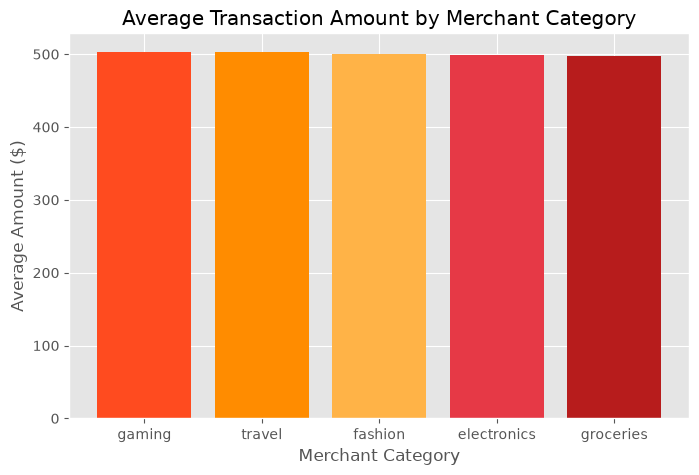

merchant_category
gaming         503.36
travel         502.71
fashion        499.96
electronics    498.26
groceries      497.89
Name: amount, dtype: float64

In [20]:
# average amount of one transaction in each category
avg_amount = df.groupby("merchant_category")["amount"].mean()
avg_amount = avg_amount.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(avg_amount.index, avg_amount.values, color=COLORS)
plt.title("Average Transaction Amount by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Average Amount ($)")
plt.show()

avg_amount.round(2)

**Observation:** The average transaction is about **\$500 in every category** (between \$497.89 and \$503.36).
Customers spend a similar amount per transaction whether they buy groceries or travel.

### 5.3 Transaction Amounts

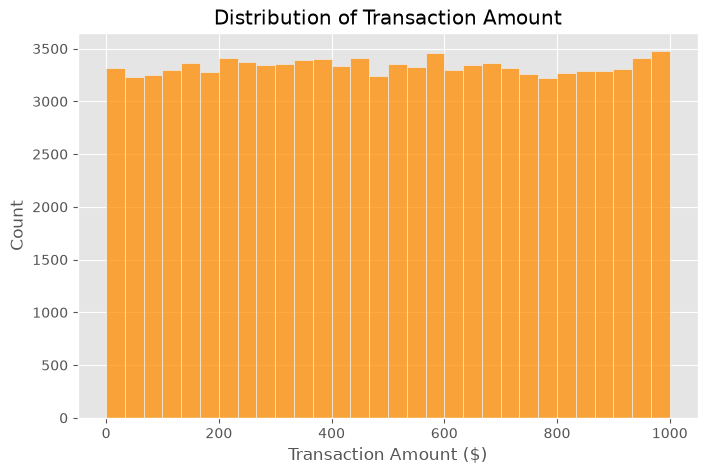

In [21]:
plt.figure(figsize=(8, 5))
sns.histplot(df["amount"], bins=30, color=ORANGE)
plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount ($)")
plt.ylabel("Count")
plt.show()

**Observation:** The histogram is almost **flat** – every amount between \$0 and \$1,000 is about equally common.
Real banking data usually has many small payments and few large ones, so this flat shape suggests the
dataset is **synthetic (computer-generated)**.

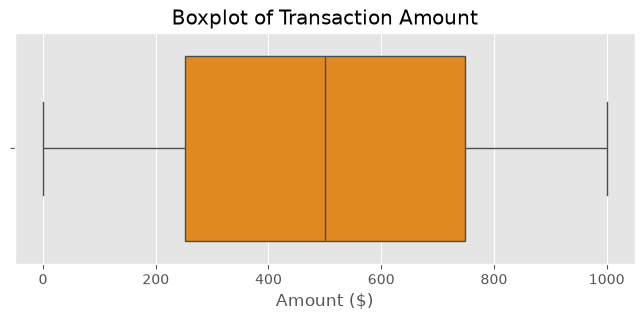

In [22]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["amount"], color=ORANGE)
plt.title("Boxplot of Transaction Amount")
plt.xlabel("Amount ($)")
plt.show()

**Observation:** The box is centred around \$500 and there are **no outliers** (no points outside the whiskers).
So no amounts had to be removed.

### 5.4 Time Patterns

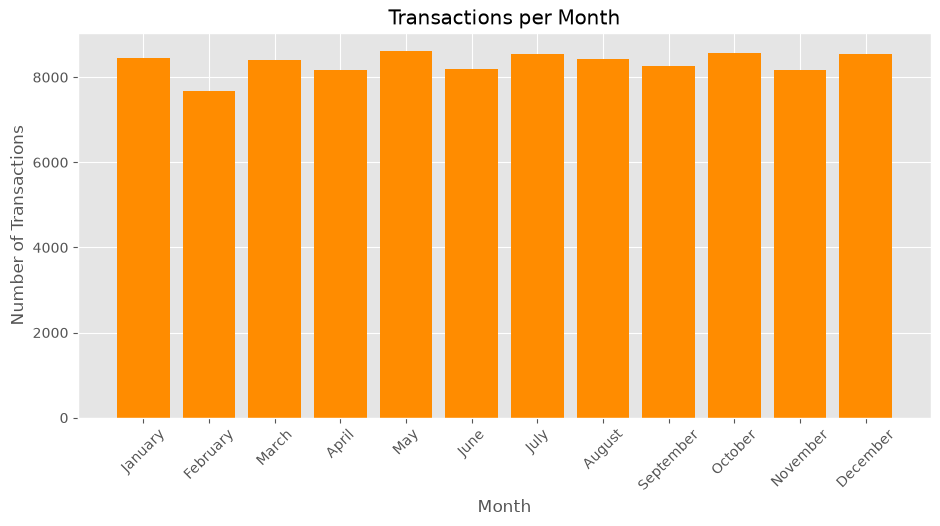

month_name
January      8442
February     7678
March        8415
April        8162
May          8614
June         8195
July         8538
August       8426
September    8253
October      8573
November     8168
December     8536
Name: count, dtype: int64

In [23]:
# transactions per month in calendar order
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]

monthly = df["month_name"].value_counts()
monthly = monthly.reindex(month_order)

plt.figure(figsize=(11, 5))
plt.bar(monthly.index, monthly.values, color=ORANGE)
plt.title("Transactions per Month")
plt.xlabel("Month")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

monthly

**Observation:** Activity is steady all year (about 8,100–8,600 per month).
**February is lowest (7,678)** mainly because it has only 28 days. 31-day months like May (8,614)
and October (8,573) are among the highest, so the number of days explains most of the difference.

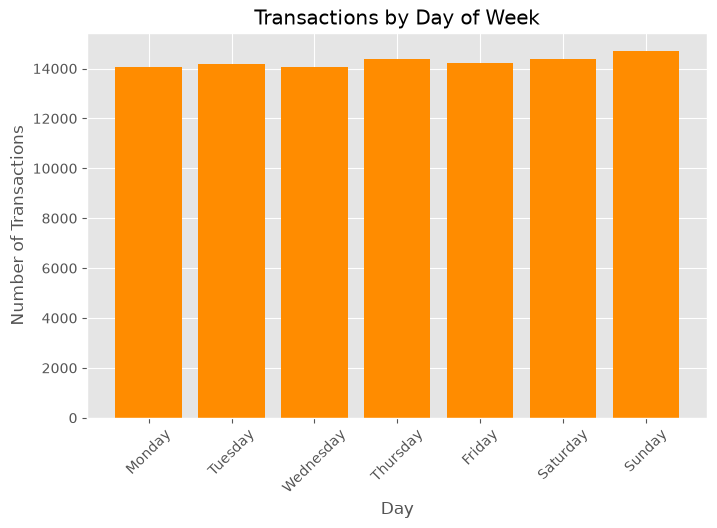

day_name
Monday       14077
Tuesday      14179
Wednesday    14076
Thursday     14377
Friday       14221
Saturday     14373
Sunday       14697
Name: count, dtype: int64

In [24]:
# transactions per weekday
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

day_count = df["day_name"].value_counts()
day_count = day_count.reindex(day_order)

plt.figure(figsize=(8, 5))
plt.bar(day_count.index, day_count.values, color=ORANGE)
plt.title("Transactions by Day of Week")
plt.xlabel("Day")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)
plt.show()

day_count

**Observation:** Every weekday has about 14,000–14,700 transactions. **Sunday is the busiest day (14,697)**,
but only about 4% above the quietest days (Monday/Wednesday). There is no strong weekday vs weekend difference.

### 5.5 Customer Behaviour

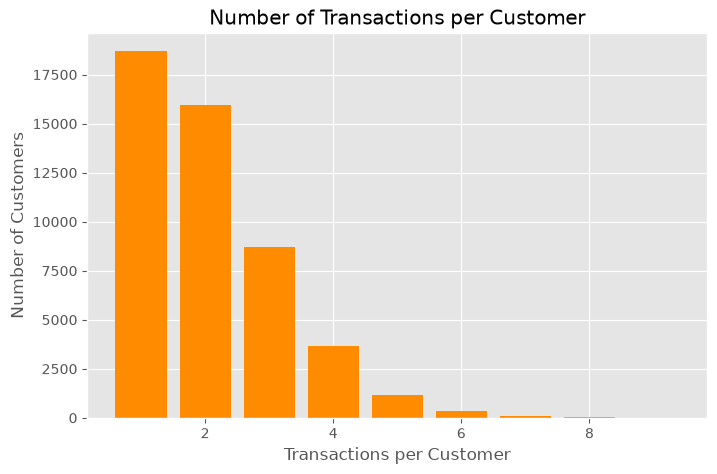

Customers with more than 1 transaction: 29934 (61.6%)


count
1    18696
2    15955
3     8704
4     3655
5     1186
6      331
7       79
8       23
9        1
Name: count, dtype: int64

In [25]:
# how many transactions does each customer have?
transactions_per_customer = df["customer_id"].value_counts()

# how many customers have 1 transaction, 2 transactions, ...
customer_groups = transactions_per_customer.value_counts().sort_index()

plt.figure(figsize=(8, 5))
plt.bar(customer_groups.index, customer_groups.values, color=ORANGE)
plt.title("Number of Transactions per Customer")
plt.xlabel("Transactions per Customer")
plt.ylabel("Number of Customers")
plt.show()

repeat_customers = (transactions_per_customer > 1).sum()
repeat_percent = repeat_customers / len(transactions_per_customer) * 100
print("Customers with more than 1 transaction:", repeat_customers, f"({repeat_percent:.1f}%)")

customer_groups

**Observation:** Most customers have **1–3 transactions** in the sample, and about **62% are repeat customers**
(2 or more transactions). Very few customers have 7 or more.
*(In the full 1M-row data, each customer has about 17 transactions on average – the sample shows fewer per customer
because it keeps only 10% of rows.)*

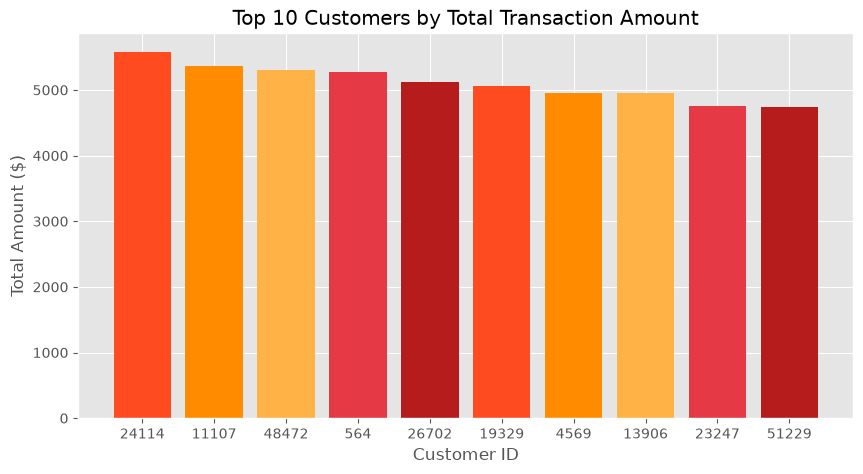

,total_amount,transactions
customer_id,,
24114,5585.95,8
11107,5363.37,8
48472,5307.65,7
564,5267.84,7
26702,5117.43,8
19329,5064.29,8
4569,4952.15,7
13906,4950.12,7
23247,4751.51,6


In [26]:
# top 10 customers by total amount spent
customer_total = df.groupby("customer_id")["amount"].sum()
top_customers = customer_total.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_customers.index.astype(str), top_customers.values, color=COLORS)
plt.title("Top 10 Customers by Total Transaction Amount")
plt.xlabel("Customer ID")
plt.ylabel("Total Amount ($)")
plt.show()

# how many transactions do these top customers have?
top_table = pd.DataFrame({
    "total_amount": top_customers.round(2),
    "transactions": transactions_per_customer[top_customers.index]
})
top_table

**Observation:** The top 10 customers each spent about **\$4,700–\$5,600**. They all have **6–8 transactions**,
compared to 1–3 for a typical customer. So top spenders are mainly the **most frequent** customers,
not people making unusually large purchases.

## 6. Fraud Analysis

**Fraud rate** = fraud transactions ÷ all transactions in a group × 100.
Using the *rate* (not the count) is fairer, because a group with more transactions will naturally have more fraud.

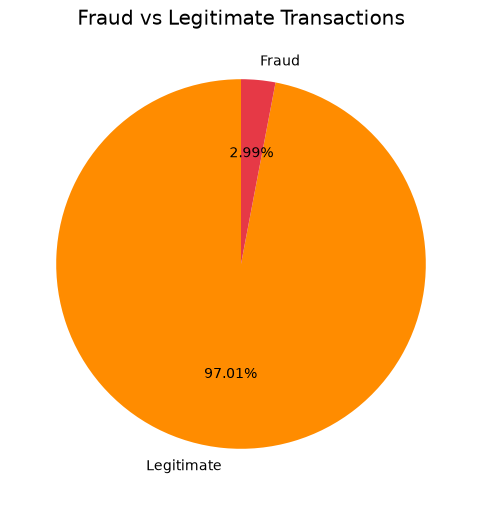

fraud_status
Legitimate    97006
Fraud          2994
Name: count, dtype: int64

In [27]:
fraud = df["fraud_status"].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(fraud, labels=fraud.index, autopct="%1.2f%%", startangle=90, colors=[ORANGE, RED])
plt.title("Fraud vs Legitimate Transactions")
plt.show()

fraud

**Observation:** **2,994 transactions (2.99%)** are fraud – about **3 in every 100**.
Fraud is rare, but at bank scale this is still a large number of cases.

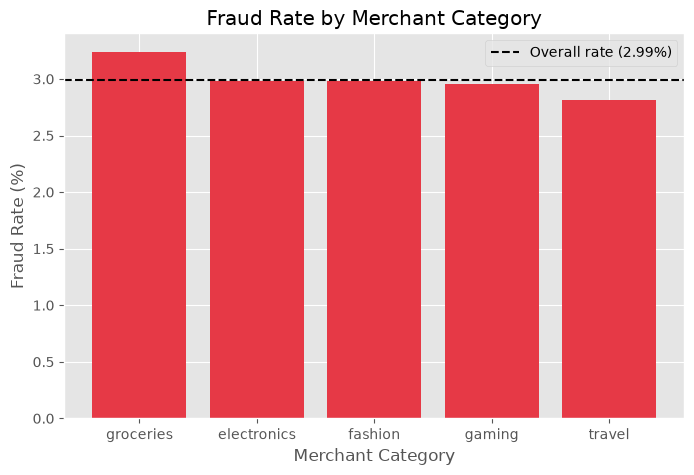

merchant_category
groceries      3.24
electronics    2.98
fashion        2.98
gaming         2.96
travel         2.81
Name: is_fraud, dtype: float64

In [28]:
# fraud rate (%) in each merchant category
# mean of a 0/1 column = share of 1s, so mean * 100 = fraud rate %
fraud_rate_category = df.groupby("merchant_category")["is_fraud"].mean() * 100
fraud_rate_category = fraud_rate_category.sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(fraud_rate_category.index, fraud_rate_category.values, color=RED)
plt.axhline(fraud_rate, color="black", linestyle="--", label=f"Overall rate ({fraud_rate:.2f}%)")
plt.title("Fraud Rate by Merchant Category")
plt.xlabel("Merchant Category")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.show()

fraud_rate_category.round(2)

**Observation:** **Groceries has the highest fraud rate (3.24%)** and **travel the lowest (2.81%)**.
All categories are close to the overall 2.99%, so merchant category on its own is only a **weak** fraud signal.

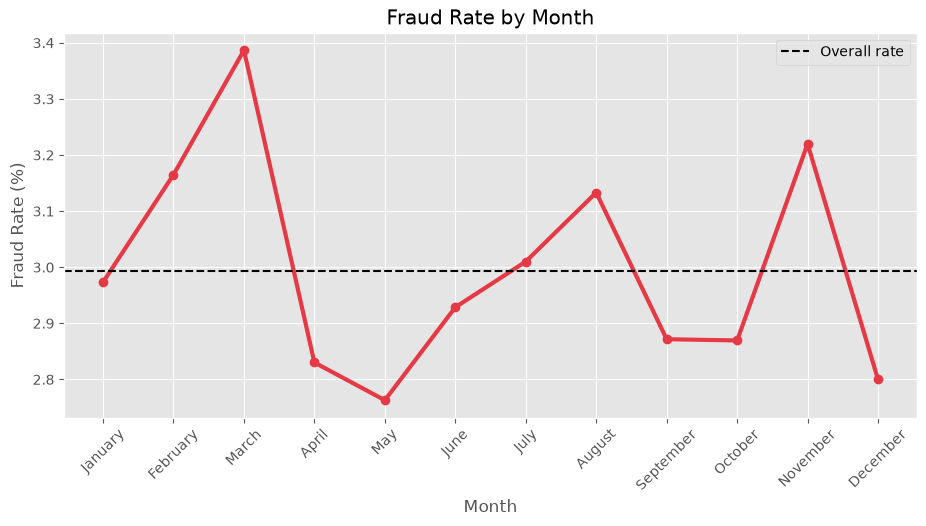

month_name
January      2.97
February     3.16
March        3.39
April        2.83
May          2.76
June         2.93
July         3.01
August       3.13
September    2.87
October      2.87
November     3.22
December     2.80
Name: is_fraud, dtype: float64

In [29]:
# fraud rate (%) by month
fraud_rate_month = df.groupby("month_name")["is_fraud"].mean() * 100
fraud_rate_month = fraud_rate_month.reindex(month_order)

plt.figure(figsize=(11, 5))
plt.plot(fraud_rate_month.index, fraud_rate_month.values, marker="o", color=RED, linewidth=3)
plt.axhline(fraud_rate, color="black", linestyle="--", label="Overall rate")
plt.title("Fraud Rate by Month")
plt.xlabel("Month")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.show()

fraud_rate_month.round(2)

**Observation:** The fraud rate moves between **2.76% (May)** and **3.39% (March)**.
There is no steady rise or fall during the year and no clear "fraud season".

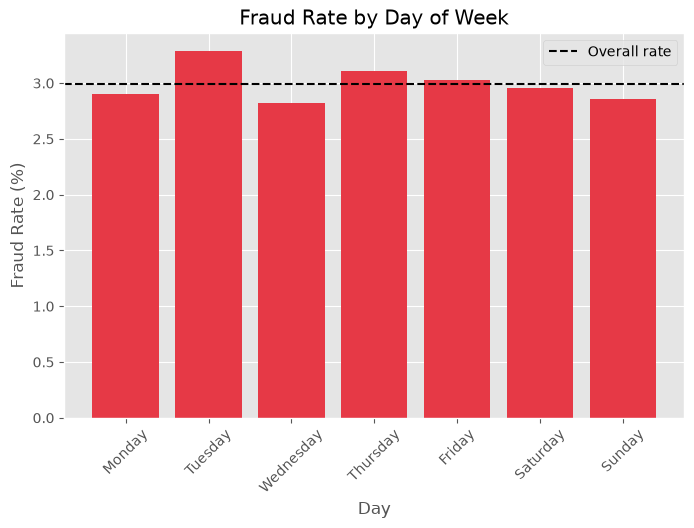

day_name
Monday       2.91
Tuesday      3.29
Wednesday    2.82
Thursday     3.11
Friday       3.02
Saturday     2.96
Sunday       2.86
Name: is_fraud, dtype: float64

In [30]:
# fraud rate (%) by weekday
fraud_rate_day = df.groupby("day_name")["is_fraud"].mean() * 100
fraud_rate_day = fraud_rate_day.reindex(day_order)

plt.figure(figsize=(8, 5))
plt.bar(fraud_rate_day.index, fraud_rate_day.values, color=RED)
plt.axhline(fraud_rate, color="black", linestyle="--", label="Overall rate")
plt.title("Fraud Rate by Day of Week")
plt.xlabel("Day")
plt.ylabel("Fraud Rate (%)")
plt.xticks(rotation=45)
plt.legend()
plt.show()

fraud_rate_day.round(2)

**Observation:** **Tuesday has the highest fraud rate (3.29%)** and Wednesday the lowest (2.82%).
Weekends are not riskier than weekdays.

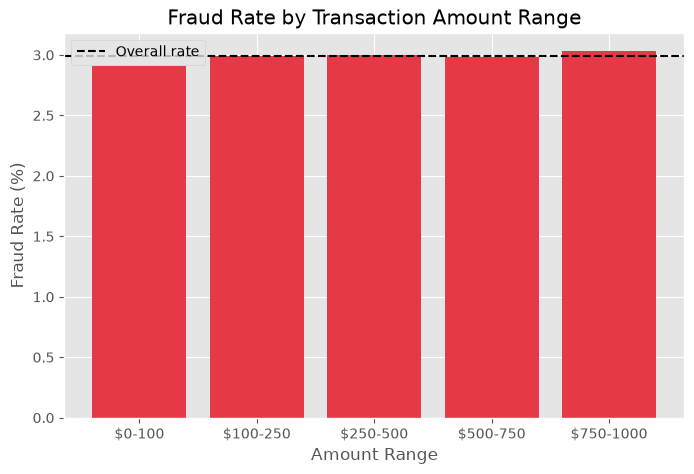

amount_range
$0-100       2.91
$100-250     2.99
$250-500     3.00
$500-750     2.98
$750-1000    3.03
Name: is_fraud, dtype: float64

In [31]:
# fraud rate (%) by amount range
fraud_rate_amount = df.groupby("amount_range", observed=True)["is_fraud"].mean() * 100

plt.figure(figsize=(8, 5))
plt.bar(fraud_rate_amount.index.astype(str), fraud_rate_amount.values, color=RED)
plt.axhline(fraud_rate, color="black", linestyle="--", label="Overall rate")
plt.title("Fraud Rate by Transaction Amount Range")
plt.xlabel("Amount Range")
plt.ylabel("Fraud Rate (%)")
plt.legend()
plt.show()

fraud_rate_amount.round(2)

**Observation:** The fraud rate is almost the same for small and large payments (**2.91% to 3.03%**).
Large transactions are **not** more likely to be fraud in this data.

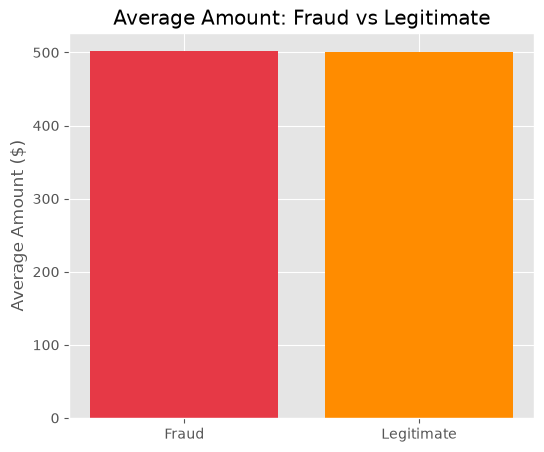

fraud_status
Fraud         501.6
Legitimate    500.4
Name: amount, dtype: float64

In [32]:
# average amount: fraud vs legitimate
avg_by_status = df.groupby("fraud_status")["amount"].mean()

plt.figure(figsize=(6, 5))
plt.bar(avg_by_status.index, avg_by_status.values, color=[RED, ORANGE])
plt.title("Average Amount: Fraud vs Legitimate")
plt.ylabel("Average Amount ($)")
plt.show()

avg_by_status.round(2)

**Observation:** Fraud transactions average **\$501.60** and legitimate ones **\$500.40** – practically the same.
Fraudsters in this data do not use unusually large (or small) amounts.

## 7. Key Findings

1. **Balanced spending:** The 5 merchant categories each get ~20% of transactions and ~\$10M in spending,
   with an average ticket of ~\$500 everywhere.
2. **Steady over time:** Transactions are spread evenly across the year; February is lowest only because it is shorter.
   Sunday is the busiest day, but only slightly.
3. **Frequent customers = top spenders:** 62% of customers are repeat customers, and the top 10 spenders are the
   people with the most transactions (6–8), not people making huge one-off purchases.
4. **Fraud rate is about 3%:** 2,994 of 100,000 transactions are fraud.
5. **Groceries is the riskiest category (3.24%)**, travel the safest (2.81%) – but the gap is small.
6. **Fraud does not depend strongly on time or amount:** the fraud rate stays between ~2.8% and ~3.4%
   for every month, weekday and amount range, and fraud and legitimate transactions have the same average amount.

## 8. Recommendations

1. **Don't rely on simple rules** like "flag large transactions" or "flag one category" – in this data they would
   miss most fraud and flag many honest customers.
2. **Monitor customer behaviour instead:** compare each transaction with that customer's own normal pattern
   (sudden change in frequency, category or amount).
3. **Give slightly more attention to groceries** and to peak-fraud periods (March, Tuesdays) as a starting point.
4. **Collect richer data** – time of day, location, device, and merchant ID – which are usually the strongest fraud signals.
5. **Build a fraud prediction model** (e.g. logistic regression / decision tree) as a next step once richer features are available.

## 9. Limitations

- The data looks **synthetic**: amounts are spread evenly and every group looks very similar, so real-world patterns may be stronger.
- **No time of day** – every timestamp is 00:00, so hourly patterns (e.g. night-time fraud) cannot be studied.
- Only **one year (2023)** of data, so year-over-year trends cannot be checked.
- We analysed a **random 10% sample** (100,000 of 1,000,000 rows). Overall rates are reliable, but per-customer counts are lower than in the full data.
- Only 5 merchant categories and no location/device information.

## 10. Conclusion

This project cleaned and analysed 100,000 banking transactions to study spending and fraud patterns.
Spending is evenly spread across categories, months and weekdays, and the top spenders are the most frequent customers.
About **3% of transactions are fraud**, and the fraud rate is similar across categories, time and amount –
groceries is slightly higher, but no single factor clearly identifies fraud.
This shows that fraud detection needs **customer-level behaviour analysis and richer data**, not just simple rules.
All results are also available in an interactive **Streamlit dashboard** (`dash.py`).